In [1]:
import numpy as np
import scipy as sc
import matplotlib.pyplot as plt
import pandas as pd
import ast

from tqdm import tqdm
from numpy.polynomial.legendre import legvander

plt.rcParams.update({'axes.xmargin': 0.0,
                     'axes.ymargin': 0.0
                    }
                   )

In [2]:
#---------------------------
# reading in |C4| timeseries
#---------------------------

C4 = pd.read_csv('|C4|.csv')
C4

,Timestamp,|C4|
0,0.00005,0.647756
1,0.00015,0.592033
2,0.00025,0.604355
3,0.00035,0.646474
4,0.00045,0.618623
...,...,...
4783,0.47955,0.034900
4784,0.47965,0.047698
4785,0.47975,0.154486
4786,0.47985,0.085782


In [14]:
#--------------------------------------
# Extracting data after acoustic cutoff
#--------------------------------------

# isolating values for model fitting
mask = (C4["Timestamp"] < 0.467) & (C4["Timestamp"] > 0.4474)

# applying mask
tCut = C4["Timestamp"][mask] 
C4Cut = C4["|C4|"][mask]

# starting time at t=0
t = np.array(tCut) - np.array(tCut)[0]

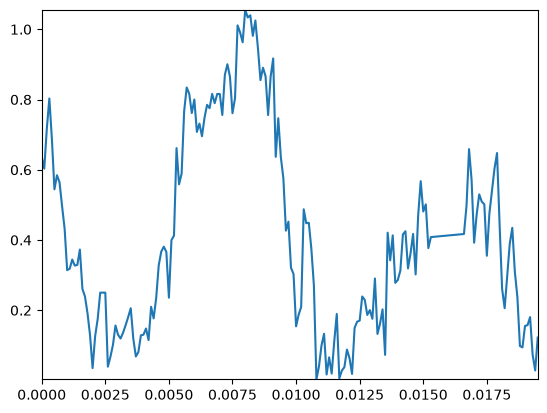

In [13]:
fig, axes = plt.subplots()

axes.plot(t, C4Cut)

In [15]:
#------------------------------------------------------------------------
# Saving data into CSV for mathematica model fitting (see modelFittin.nb)
#------------------------------------------------------------------------

data = pd.DataFrame({'Time': t, '|C4|': C4Cut})
data.to_csv('|C4|-shifted.csv', index=False)